# Laboratory Work #2 — Product Reviews Dataset & EDA

1.   List item
2.   List item



## Assignment

**Topic:** Building a small review dataset and exploring it with pandas

**Goal:** Learn how to create a tiny tabular dataset, compute basic sample statistics, and make simple conclusions about data quality.

### Tasks
1. **Create a dataset** of 10 product reviews (manually prepared example).
2. **Perform EDA** — sample size, missing values, descriptive statistics, simple charts.
3. **Analyze the data with pandas** and write short conclusions about the sample.

> This notebook is an **example solution**. Comments and explanations are in English.

## 0. Import libraries

In [ ]:
# Import libraries used for tables and simple plots
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Create a small dataset (10 product reviews)

In this example we do **not** scrape the web.
We create a mini-dataset by hand: 10 customer reviews for different products.

Each review has:
- `product` — product name
- `category` — product category
- `rating` — score from 1 to 5
- `review_text` — short customer comment
- `helpful_votes` — how many people found the review helpful

In [ ]:
# Manual example dataset: 10 product reviews
data = {
    "product": [
        "Wireless Headphones X200",
        "Smart Watch FitPro",
        "USB-C Charger 65W",
        "Laptop Stand Aluminum",
        "Bluetooth Speaker Mini",
        "Mechanical Keyboard K8",
        "Webcam HD 1080p",
        "Phone Case ClearShield",
        "Portable SSD 1TB",
        "LED Desk Lamp SoftLight",
    ],
    "category": [
        "Audio",
        "Wearables",
        "Accessories",
        "Accessories",
        "Audio",
        "Computers",
        "Computers",
        "Accessories",
        "Storage",
        "Home",
    ],
    "rating": [5, 4, 5, 3, 2, 4, 5, 3, 4, 1],
    "review_text": [
        "Great sound and comfortable for long calls.",
        "Nice design, battery lasts almost two days.",
        "Charges my laptop fast, no overheating.",
        "Stable, but a bit too tall for my desk.",
        "Sound is weak and bass is almost missing.",
        "Keys feel good, RGB lighting is bright.",
        "Sharp image, easy to use for online meetings.",
        "Looks fine, but yellowed after one month.",
        "Fast transfer speed, compact and reliable.",
        "Stopped working after one week. Very disappointed.",
    ],
    "helpful_votes": [12, 8, 15, 3, 6, 9, 11, 2, 14, 7],
}

# Create a pandas DataFrame from the dictionary
df = pd.DataFrame(data)

# Show the full sample
df

,product,category,rating,review_text,helpful_votes
0,Wireless Headphones X200,Audio,5,Great sound and comfortable for long calls.,12
1,Smart Watch FitPro,Wearables,4,"Nice design, battery lasts almost two days.",8
2,USB-C Charger 65W,Accessories,5,"Charges my laptop fast, no overheating.",15
3,Laptop Stand Aluminum,Accessories,3,"Stable, but a bit too tall for my desk.",3
4,Bluetooth Speaker Mini,Audio,2,Sound is weak and bass is almost missing.,6
5,Mechanical Keyboard K8,Computers,4,"Keys feel good, RGB lighting is bright.",9
6,Webcam HD 1080p,Computers,5,"Sharp image, easy to use for online meetings.",11
7,Phone Case ClearShield,Accessories,3,"Looks fine, but yellowed after one month.",2
8,Portable SSD 1TB,Storage,4,"Fast transfer speed, compact and reliable.",14
9,LED Desk Lamp SoftLight,Home,1,Stopped working after one week. Very disappoin...,7


## 2. Exploratory Data Analysis (EDA)

Here we look at the structure of the sample and basic statistics.

In [ ]:
# Sample size and column types
print("Number of reviews:", len(df))
print("Number of columns:", df.shape[1])
print("\nColumn names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Number of reviews: 10
Number of columns: 5

Column names: ['product', 'category', 'rating', 'review_text', 'helpful_votes']

Data types:
product          object
category         object
rating            int64
review_text      object
helpful_votes     int64
dtype: object


In [ ]:
# Check missing values (important for data quality)
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
product          0
category         0
rating           0
review_text      0
helpful_votes    0
dtype: int64


In [ ]:
# Descriptive statistics for numeric columns
# count, mean, std, min, 25%, 50% (median), 75%, max
df[["rating", "helpful_votes"]].describe()

,rating,helpful_votes
count,10.000000,10.000000
mean,3.600000,8.700000
std,1.349897,4.372896
min,1.000000,2.000000
25%,3.000000,6.250000
50%,4.000000,8.500000
75%,4.750000,11.750000
max,5.000000,15.000000


In [ ]:
# Add a simple text feature: length of each review (in characters)
df["review_length"] = df["review_text"].str.len()

print("Average review length (characters):", round(df["review_length"].mean(), 1))
print("Shortest review:", df["review_length"].min())
print("Longest review:", df["review_length"].max())

df[["product", "review_length"]]

Average review length (characters): 42.2
Shortest review: 39
Longest review: 50


,product,review_length
0,Wireless Headphones X200,43
1,Smart Watch FitPro,43
2,USB-C Charger 65W,39
3,Laptop Stand Aluminum,39
4,Bluetooth Speaker Mini,41
5,Mechanical Keyboard K8,39
6,Webcam HD 1080p,45
7,Phone Case ClearShield,41
8,Portable SSD 1TB,42
9,LED Desk Lamp SoftLight,50


In [ ]:
# Frequency tables for categorical / discrete fields
print("Rating distribution:")
print(df["rating"].value_counts().sort_index())

print("\nCategory distribution:")
print(df["category"].value_counts())

Rating distribution:
rating
1    1
2    1
3    2
4    3
5    3
Name: count, dtype: int64

Category distribution:
category
Accessories    3
Audio          2
Computers      2
Wearables      1
Storage        1
Home           1
Name: count, dtype: int64


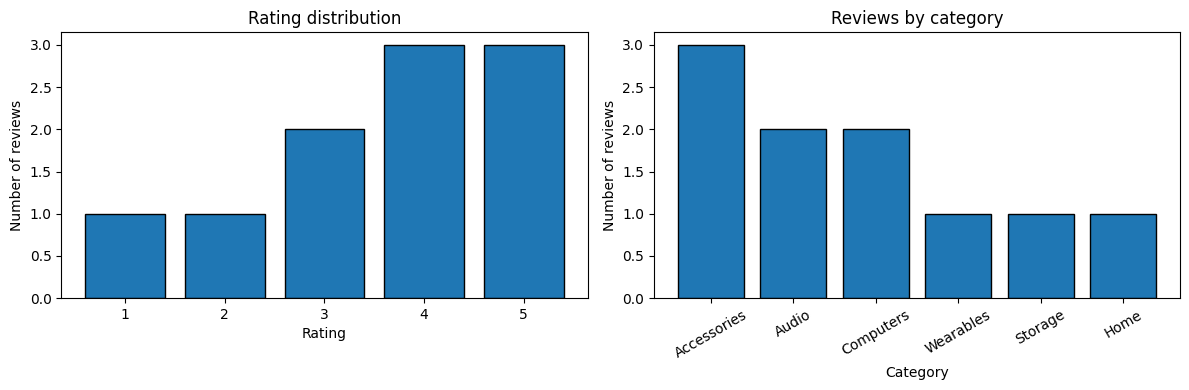

In [ ]:
# Simple charts for visual EDA
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Rating bar chart
rating_counts = df["rating"].value_counts().sort_index()
axes[0].bar(rating_counts.index.astype(str), rating_counts.values, edgecolor="black")
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of reviews")

# Category bar chart
category_counts = df["category"].value_counts()
axes[1].bar(category_counts.index, category_counts.values, edgecolor="black")
axes[1].set_title("Reviews by category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Number of reviews")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 3. Analyze the data with pandas

In [ ]:
# Average rating and helpful votes by category
category_stats = (
    df.groupby("category")[["rating", "helpful_votes", "review_length"]]
      .mean()
      .round(2)
      .sort_values("rating", ascending=False)
)

category_stats

,rating,helpful_votes,review_length
category,,,
Computers,4.50,10.00,42.00
Storage,4.00,14.00,42.00
Wearables,4.00,8.00,43.00
Accessories,3.67,6.67,39.67
Audio,3.50,9.00,42.00
Home,1.00,7.00,50.00


In [ ]:
# Positive reviews: rating >= 4
positive = df[df["rating"] >= 4]
print("Number of positive reviews:", len(positive))
positive[["product", "rating", "review_text"]]

Number of positive reviews: 6


,product,rating,review_text
0,Wireless Headphones X200,5,Great sound and comfortable for long calls.
1,Smart Watch FitPro,4,"Nice design, battery lasts almost two days."
2,USB-C Charger 65W,5,"Charges my laptop fast, no overheating."
5,Mechanical Keyboard K8,4,"Keys feel good, RGB lighting is bright."
6,Webcam HD 1080p,5,"Sharp image, easy to use for online meetings."
8,Portable SSD 1TB,4,"Fast transfer speed, compact and reliable."


In [ ]:
# Negative reviews: rating <= 2
negative = df[df["rating"] <= 2]
print("Number of negative reviews:", len(negative))
negative[["product", "rating", "review_text"]]

Number of negative reviews: 2


,product,rating,review_text
4,Bluetooth Speaker Mini,2,Sound is weak and bass is almost missing.
9,LED Desk Lamp SoftLight,1,Stopped working after one week. Very disappoin...


In [ ]:
# Correlation between rating and helpful votes
# Close to 0 = weak linear relationship
corr = df["rating"].corr(df["helpful_votes"])
print("Correlation between rating and helpful_votes:", round(corr, 3))

Correlation between rating and helpful_votes: 0.655


In [ ]:
# Final summary numbers for conclusions
print("Sample size:", len(df))
print("Average rating:", round(df["rating"].mean(), 2))
print("Median rating:", df["rating"].median())
print("Most common category:", df["category"].mode().iloc[0])
print("Share of positive reviews (rating >= 4):",
      round(100 * len(positive) / len(df), 1), "%")
print("Share of negative reviews (rating <= 2):",
      round(100 * len(negative) / len(df), 1), "%")

Sample size: 10
Average rating: 3.6
Median rating: 4.0
Most common category: Accessories
Share of positive reviews (rating >= 4): 60.0 %
Share of negative reviews (rating <= 2): 20.0 %


## 4. Conclusions about this sample

1. The sample contains **10 product reviews** across several categories (Audio, Accessories, Computers, etc.).
2. There are **no missing values**, so the dataset is clean and easy to analyze.
3. The average rating is moderately high, but the sample also includes clear negative reviews (ratings 1–2).
4. Categories are **not balanced** (Accessories appears more often than Storage or Home), so conclusions by category should be careful.
5. Because the sample is very small (n = 10), statistics are only illustrative and **cannot represent the full market**.
6. Overall data quality is good for a teaching example: fields are consistent, ratings are in range 1–5, and texts are short but readable.

---

## Independent assignment for students

<!--
STUDENT TASK (independent work)

Reproduce the same laboratory work, but for REAL movie reviews.

What you need to do:
1. Collect 20 movie reviews from a real website
   (manually copy-paste OR scrape with BeautifulSoup).
   Suggested sources for practice: IMDb, Letterboxd, Rotten Tomatoes, or any open review page.
2. Build a pandas DataFrame with at least these columns:
   - movie_title
   - rating (numeric)
   - review_text
   - (optional) author, date, helpful_votes, language
3. Perform the same EDA steps as in this notebook:
   - sample size and dtypes
   - missing values
   - describe() for numeric fields
   - review length
   - rating / category distributions and simple plots
4. Analyze the data with pandas (groupBy, filters for positive/negative reviews, correlation).
5. Write a short evaluation of SAMPLE QUALITY:
   - Is n = 20 enough?
   - Are ratings balanced?
   - Are texts informative?
   - Any bias (only one movie, only English, only 5-star reviews, etc.)?

Submit: Colab notebook + 5–7 conclusions in English.
-->

**Independent task:** reproduce this lab for **real movie reviews**.

1. Take **20 reviews** from a real website (copy manually or use `bs4`).
2. Build a DataFrame and repeat the same EDA + pandas analysis.
3. Give your own feedback on the **quality of the sample** (size, balance, bias, missing data, usefulness of texts).

Submit a Colab notebook with code, charts, and 5–7 conclusions in English.

---

# Independent assignment — real movie reviews (my solution)

**Source:** [Metacritic](https://www.metacritic.com) user reviews (public pages, scraped with `requests` + `BeautifulSoup`).

**Plan:** take **5 reviews from each of 4 movies** = **20 real reviews**. I picked movies with very different
reputations (a classic, a recent hit, and two badly received films) so that the ratings are not all 5-star.

Columns: `movie_title`, `rating` (Metacritic user score 0–10), `review_text`, `author`, `date`.

## 1. Collect 20 real reviews with BeautifulSoup

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import time

# Movies to collect: Metacritic URL name -> readable title
MOVIES = {
    "inception": "Inception",
    "barbie": "Barbie",
    "joker-folie-a-deux": "Joker: Folie a Deux",
    "morbius": "Morbius",
}
REVIEWS_PER_MOVIE = 5

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/124.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
}


def scrape_metacritic_reviews(slug, title, n):
    """Download the public user-review page of one movie and return n reviews."""
    url = f"https://www.metacritic.com/movie/{slug}/user-reviews/"
    response = requests.get(url, headers=HEADERS, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")

    reviews = []
    # Every user review has a small score circle; its card holds the rest of the review
    for score_tag in soup.select(".c-siteReviewScore_medium"):
        card = score_tag.find_parent("div", class_="bg-gray-50")
        text_tag = card.select_one(".line-clamp-5") if card else None
        if text_tag is None:
            continue
        author_tag = card.select_one("a[href^='/user/']")
        date_tag = card.select_one("div.text-xs.leading-6")
        reviews.append({
            "movie_title": title,
            "rating": int(score_tag.get_text(strip=True)),
            "review_text": text_tag.get_text(" ", strip=True),
            "author": author_tag["href"].strip("/").split("/")[-1] if author_tag else None,
            "date": date_tag.get_text(strip=True) if date_tag else None,
        })
        if len(reviews) == n:
            break
    return reviews


all_reviews = []
for slug, title in MOVIES.items():
    movie_reviews = scrape_metacritic_reviews(slug, title, REVIEWS_PER_MOVIE)
    print(f"{title}: {len(movie_reviews)} reviews")
    all_reviews.extend(movie_reviews)
    time.sleep(1)  # be polite to the website

movies_df = pd.DataFrame(all_reviews)
movies_df["date"] = pd.to_datetime(movies_df["date"], errors="coerce")

# Save a copy so the analysis can be repeated even if the website changes
movies_df.to_csv("movie_reviews.csv", index=False)
movies_df.head()

## 2. EDA

In [ ]:
# Sample size and column types
print("Number of reviews:", len(movies_df))
print("Number of columns:", movies_df.shape[1])
print("\nColumn names:", list(movies_df.columns))
print("\nData types:")
print(movies_df.dtypes)

In [ ]:
# Missing values per column
print("Missing values per column:")
print(movies_df.isna().sum())

In [ ]:
# Review length: characters and words
movies_df["review_length"] = movies_df["review_text"].str.len()
movies_df["word_count"] = movies_df["review_text"].str.split().str.len()

# Descriptive statistics for numeric columns
movies_df[["rating", "review_length", "word_count"]].describe().round(2)

In [ ]:
print("Average review length (characters):", round(movies_df["review_length"].mean(), 1))
print("Shortest review:", movies_df["review_length"].min())
print("Longest review:", movies_df["review_length"].max())

movies_df[["movie_title", "author", "rating", "review_length"]]

In [ ]:
# Simple language guess: count common "small words" of each language in the review
STOP_WORDS = {
    "English":    "the and is it this of to was in that with for not but".split(),
    "Spanish":    "el la de que y es en un una los las por pero muy".split(),
    "Portuguese": "o a de que e é um uma do da não com mas muito".split(),
    "French":     "le la les de et est un une pas que je très".split(),
    "German":     "der die das und ist nicht ein eine ich sehr mit".split(),
    "Italian":    "il la di che e è un una non per molto".split(),
}

def guess_language(text):
    words = text.lower().split()
    scores = {lang: sum(w in sw for w in words) for lang, sw in STOP_WORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "unknown"

movies_df["language"] = movies_df["review_text"].apply(guess_language)
print("Reviews per language (rough guess):")
print(movies_df["language"].value_counts())

In [ ]:
# Frequency tables
print("Rating distribution (0-10):")
print(movies_df["rating"].value_counts().sort_index())

print("\nReviews per movie:")
print(movies_df["movie_title"].value_counts())

In [ ]:
# Simple charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

rating_counts = movies_df["rating"].value_counts().reindex(range(11), fill_value=0)
axes[0].bar(rating_counts.index.astype(str), rating_counts.values, edgecolor="black")
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("Rating (0-10)")
axes[0].set_ylabel("Number of reviews")

avg_by_movie = movies_df.groupby("movie_title")["rating"].mean().sort_values()
axes[1].barh(avg_by_movie.index, avg_by_movie.values, edgecolor="black")
axes[1].set_title("Average rating by movie")
axes[1].set_xlabel("Average rating")
axes[1].set_xlim(0, 10)

axes[2].hist(movies_df["word_count"], bins=10, edgecolor="black")
axes[2].set_title("Review length")
axes[2].set_xlabel("Words per review")
axes[2].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

## 3. Analyze the data with pandas

In [ ]:
# Average rating and review length by movie
movie_stats = (
    movies_df.groupby("movie_title")
      .agg(reviews=("rating", "size"),
           avg_rating=("rating", "mean"),
           min_rating=("rating", "min"),
           max_rating=("rating", "max"),
           avg_words=("word_count", "mean"))
      .round(2)
      .sort_values("avg_rating", ascending=False)
)
movie_stats

In [ ]:
# Positive reviews: rating >= 7 (Metacritic counts 7-10 as positive)
positive = movies_df[movies_df["rating"] >= 7]
print("Number of positive reviews:", len(positive))
positive[["movie_title", "rating", "word_count"]]

In [ ]:
# Negative reviews: rating <= 4 (Metacritic counts 0-4 as negative)
negative = movies_df[movies_df["rating"] <= 4]
print("Number of negative reviews:", len(negative))
negative[["movie_title", "rating", "word_count"]]

In [ ]:
# Correlation between rating and review length
# Close to 0 = weak linear relationship
corr = movies_df["rating"].corr(movies_df["word_count"])
print("Correlation between rating and word_count:", round(corr, 3))

In [ ]:
# Final summary numbers for conclusions
mixed = len(movies_df) - len(positive) - len(negative)
print("Sample size:", len(movies_df))
print("Number of movies:", movies_df["movie_title"].nunique())
print("Average rating:", round(movies_df["rating"].mean(), 2))
print("Median rating:", movies_df["rating"].median())
print("Share of positive reviews (7-10):", round(100 * len(positive) / len(movies_df), 1), "%")
print("Share of mixed reviews (5-6):", round(100 * mixed / len(movies_df), 1), "%")
print("Share of negative reviews (0-4):", round(100 * len(negative) / len(movies_df), 1), "%")
print("Reviews shorter than 20 words:", (movies_df["word_count"] < 20).sum())
print("Date range:", movies_df["date"].min().date(), "to", movies_df["date"].max().date())
print("Share of English reviews:", round(100 * (movies_df["language"] == "English").mean(), 1), "%")

## 4. Conclusions and sample quality

*(Numbers are from my run on 18 Nov 2026. The website keeps getting new reviews, so a new run can give slightly different values.)*

1. **Sample size:** the sample has **20 real reviews from 4 movies** (5 per movie). There are **no missing values**, so the data is clean. But n = 20 is **too small** to make general claims: 5 reviews per movie can't represent what all viewers think.
2. **Rating balance:** the ratings are **polarized** rather than balanced. In my run, about **40% were positive (7–10)**, **45% negative (0–4)**, and only **15% mixed (5–6)**. The average was **5.1**, but the standard deviation of about 4 shows that most people gave either very high or very low scores. Online user reviews often look like this, because people with strong opinions are more likely to write one.
3. **Differences between movies:** *Inception* got almost only top scores (about 9.8), while *Morbius* and *Joker: Folie a Deux* were mostly negative. The movie explains most of the variation in rating, so mixing movies matters a lot for any analysis.
4. **Usefulness of the texts:** the length varies a lot, from about 6 to 290 words. About **a third of the reviews are shorter than 20 words** ("10/10 masterpiece"-style), which carry little information for NLP. The longer reviews explain their reasons and are much more useful.
5. **Rating vs length:** the correlation between rating and word count is **weak (about 0.18)**, so long reviews are not clearly more positive or more negative.
6. **Language bias:** Metacritic is an English site, but my rough language check found that **only about half of the reviews are in English**; the others are in Spanish, Portuguese, French, or German. For an English NLP task I would have to filter by language or translate.
7. **Other biases:** the reviews come from **one website** and from users who chose to write a review. I took the first reviews shown on each page, not a random sample. The movies were picked by hand. To improve the sample I would collect more reviews per movie (for example 100+), pick them at random, and use several websites.